[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch58_LabCh58_DQN_CartPole.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 58: Deep Reinforcement Learning** (Part XII: Other Shapes of Data).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=58](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=58)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch58 - A deep Q-network balances a pole
## Cart-pole in NumPy, a 4,610-parameter network, a shuffled memory and a frozen copy

This lab goes with **Chapter 58** of *The Why Book of Deep Learning, Part 2*.

Chapter 57's agent kept a table with one row per state. This lab's world has no rows to count: its state
is four real numbers. So the table is replaced by a small Keras network that takes the four numbers and
returns a value for each action. That one swap is the whole of "deep" reinforcement learning, and it
breaks the learning rule in two ways that this lab lets you watch. You will build the two standard
repairs (a replay memory and a target network), then take each one out again and see what happens.

| The miniature | value |
|---|---|
| world | a pole hinged on a cart; written here in NumPy, no environment library |
| state | 4 numbers: cart position, cart velocity, pole angle, pole angular velocity |
| actions | 2: push left, push right (always one or the other) |
| reward | +1 for every step the pole is still up |
| Q-network | Dense 4 -> 64 -> 64 -> 2, 4,610 parameters |
| training | 20,000 steps of experience per run (400 seconds of simulated time), three seeds per agent |
| time limit | 200 steps per training episode, applied in the loop, not by the world |
| second agent | REINFORCE, a policy network Dense 4 -> 32 -> 2, 226 parameters |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Write a physical environment with `reset()` and `step(action)` and test its physics | Steps 2 and 3 |
| Say why a table cannot hold this problem, and count the network that replaces it | Steps 5 and 6 |
| Build a replay memory, and say what it is for | Step 7 |
| Write the DQN update: target, stopped gradient, Huber loss, end-of-episode mask | Step 8 |
| Train a DQN and read a noisy learning curve | Steps 9 to 11 |
| Show what removing replay, or the target network, does | Steps 12 and 13 |
| Report a result over several seeds, with its spread | Step 14 |
| Write REINFORCE as "classification, weighted by the return", and explain the baseline | Steps 15 and 16 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**.

> **Runtime:** two to four minutes on a laptop CPU. No GPU is needed and nothing is downloaded.

> **Honest scale:** this is a miniature. Cart-pole is the "hello world" of the subject: four inputs, two
> actions, and a hand-written rule of one line solves it (Step 4). Each agent here gets 20,000 steps of
> experience. The systems the chapter describes used millions to billions. What carries over is the
> machinery and the habits, not the scores.

> **Your numbers will differ a little.** Reinforcement learning amplifies tiny differences: a last-digit
> change in one weight changes one action, which changes every state after it. The numbers quoted in the
> chapter are from the saved run of this notebook. Yours should tell the same story with other digits.

---
## Step 1 - Imports and seeds

In [1]:
import os, time, math
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.set_printoptions(precision=3, suppress=True, linewidth=110)
T_START = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| NumPy", np.__version__)

TensorFlow 2.21.0 | Keras 3.14.1 | NumPy 2.4.6


## Step 2 - The world: a pole on a cart

A cart runs on a track. A pole is hinged to the top of the cart and is free to fall to the left or the
right. Fifty times a second the agent must push the cart, with a force of 10 newtons, either to the left
(action 0) or to the right (action 1). There is no "do nothing". The episode ends when the pole leans
more than 12 degrees from upright or the cart is more than 2.4 metres from the centre of the track.

The **state** is four numbers: cart position `x` (metres, positive to the right), cart velocity, pole
angle `theta` (radians, zero is upright, positive leans right) and pole angular velocity.

The class has the same two methods as Chapter 57's maze: `reset()` returns the state, and `step(action)`
returns `(state, reward, done)`. The reward is +1 for every step, including the last one. `done` is true
only when the pole has fallen or the cart has left the track. The time limit is not the world's
business: the training loop applies it, as in Chapter 57.

The physics is in `accelerations`. It is the standard pair of equations for this system, and Step 3
checks them instead of trusting them. `advance` moves time forward by 0.02 seconds with the simplest
possible rule (Euler's): new position = old position + time step x velocity, and the same for velocities.

**Predict before you run:** the cart and pole together weigh 1.1 kg and the push is 10 newtons. Roughly
what acceleration do you expect for the cart? In which direction will the pole start to tip?

In [2]:
class CartPole:
    """reset() -> state.  step(action) -> (state, reward, done).
    state = [x, x velocity, theta, theta velocity]; action 0 pushes left, 1 pushes right."""
    GRAVITY, M_CART, M_POLE = 9.8, 1.0, 0.1
    HALF_LEN = 0.5                    # half the pole's length, in metres (the pole is 1 m long)
    FORCE, DT = 10.0, 0.02            # newtons per push; seconds per step
    X_LIMIT, ANGLE_LIMIT = 2.4, 12 * math.pi / 180

    def __init__(self, seed=0):
        self.rng = np.random.default_rng(seed)       # the world's own dice (used only by reset)
        self.state = None

    def accelerations(self, state, force):
        """The physics: (cart acceleration, pole angular acceleration) for a horizontal force on the cart."""
        x, x_vel, th, th_vel = state
        total = self.M_CART + self.M_POLE
        ml = self.M_POLE * self.HALF_LEN
        sin, cos = math.sin(th), math.cos(th)
        temp = (force + ml * th_vel ** 2 * sin) / total
        th_acc = (self.GRAVITY * sin - cos * temp) / (self.HALF_LEN * (4 / 3 - self.M_POLE * cos ** 2 / total))
        x_acc = temp - ml * th_acc * cos / total
        return x_acc, th_acc

    def advance(self, state, force):
        """One Euler step of 0.02 s: positions move by their velocities, velocities by their accelerations."""
        x, x_vel, th, th_vel = state
        x_acc, th_acc = self.accelerations(state, force)
        return np.array([x + self.DT * x_vel, x_vel + self.DT * x_acc,
                         th + self.DT * th_vel, th_vel + self.DT * th_acc])

    def failed(self, state):
        return bool(abs(state[0]) > self.X_LIMIT or abs(state[2]) > self.ANGLE_LIMIT)

    def reset(self):
        self.state = self.rng.uniform(-0.05, 0.05, size=4)       # nearly upright, nearly still
        return self.state.copy()

    def step(self, action):
        self.state = self.advance(self.state, self.FORCE if action == 1 else -self.FORCE)
        return self.state.copy(), 1.0, self.failed(self.state)

env = CartPole(seed=58)
s = env.reset()
print("reset() ->", s, "  shape", s.shape)
for a in (1, 1, 0):
    s, r, done = env.step(a)
    print(f"step({a}) [{'left ' if a == 0 else 'right'}] -> state {s}, reward {r}, done {done}")
print(f"\nangle limit: {CartPole.ANGLE_LIMIT:.4f} rad = 12 degrees; track limit: {CartPole.X_LIMIT} m; one step = {CartPole.DT} s")

reset() -> [-0.019  0.038 -0.026 -0.029]   shape (4,)
step(1) [right] -> state [-0.018  0.233 -0.026 -0.33 ], reward 1.0, done False
step(1) [right] -> state [-0.014  0.429 -0.033 -0.631], reward 1.0, done False
step(0) [left ] -> state [-0.005  0.234 -0.045 -0.349], reward 1.0, done False

angle limit: 0.2094 rad = 12 degrees; track limit: 2.4 m; one step = 0.02 s


## Step 3 - Do not trust the physics: test it

Equations copied from memory are a classic source of silent bugs: a wrong sign gives a world that still
runs and still pays rewards, and an agent will dutifully learn to balance a pole that falls upwards. So
we test the world before anything learns in it. Four checks:

1. **Upright and still, no force:** nothing should move.
2. **Tilted a little to the right, no force:** the pole must fall further to the right (and, since nothing
   pushes the pair from outside, the cart must slide the other way).
3. **Upright, pushed to the right:** the cart must accelerate to the right and the pole must tip to the
   left, the way a broom tips back when you move your hand forwards.
4. **The two balance laws.** The accelerations must satisfy Newton's law for the cart and pole together,
   `(M + m) x_acc + m l (th_acc cos - th_vel^2 sin) = force`, and the turning law for the pole about its
   hinge, `(4/3) l th_acc + x_acc cos = g sin` (the 4/3 is what a uniform rod turning about its end
   contributes). We check both at 1,000 random states. Any formula that passes is the right physics,
   whatever it looks like.

**Predict before you run:** left alone from a tilt of 0.05 radians, how many steps (of 0.02 s) until the
pole passes 12 degrees? If the agent pushes right on every step, how many steps does an episode last?

In [3]:
world = CartPole()
M, m, l, g = world.M_CART, world.M_POLE, world.HALF_LEN, world.GRAVITY

xa, tha = world.accelerations([0, 0, 0, 0], 0.0)
print(f"1. upright, no force      : cart acceleration {xa:+.3f}, pole acceleration {tha:+.3f}")
assert xa == 0 and tha == 0

xa, tha = world.accelerations([0, 0, 0.05, 0], 0.0)
print(f"2. tilted right, no force : cart acceleration {xa:+.3f}, pole acceleration {tha:+.3f}")
assert tha > 0 and xa < 0, "a pole tilted right must fall right, and push the cart left"

xa, tha = world.accelerations([0, 0, 0, 0], world.FORCE)
print(f"3. upright, pushed right  : cart acceleration {xa:+.3f}, pole acceleration {tha:+.3f}")
assert xa > 0 and tha < 0, "a push to the right must move the cart right and tip the pole left"
xa2, tha2 = world.accelerations([0, 0, 0, 0], -world.FORCE)
assert xa2 == -xa and tha2 == -tha, "left and right must mirror each other"

rng = np.random.default_rng(0)
worst = 0.0
for _ in range(1000):
    st = rng.uniform([-2.4, -3, -0.3, -3], [2.4, 3, 0.3, 3])
    F = rng.choice([-10.0, 0.0, 10.0])
    xa, tha = world.accelerations(st, F)
    sin, cos = math.sin(st[2]), math.cos(st[2])
    newton = (M + m) * xa + m * l * (tha * cos - st[3] ** 2 * sin) - F
    turning = (4 / 3) * l * tha + xa * cos - g * sin
    worst = max(worst, abs(newton), abs(turning))
print(f"4. both balance laws at 1,000 random states: largest imbalance {worst:.1e}")
assert worst < 1e-9

def steps_until_failure(state, force_of, limit=1000):
    state = np.array(state, dtype=float)
    for t in range(1, limit + 1):
        state = world.advance(state, force_of(state))
        if world.failed(state): return t
    return limit

n_free = steps_until_failure([0, 0, 0.05, 0], lambda st: 0.0)
n_right = steps_until_failure([0, 0, 0, 0], lambda st: world.FORCE)
print(f"\nleft alone from a tilt of 0.05 rad, the pole passes 12 degrees after {n_free} steps ({n_free * world.DT:.2f} s)")
print(f"pushed right on every step from upright, the episode lasts {n_right} steps")

1. upright, no force      : cart acceleration +0.000, pole acceleration +0.000
2. tilted right, no force : cart acceleration -0.036, pole acceleration +0.788
3. upright, pushed right  : cart acceleration +9.756, pole acceleration -14.634
4. both balance laws at 1,000 random states: largest imbalance 4.0e-15

left alone from a tilt of 0.05 rad, the pole passes 12 degrees after 28 steps (0.56 s)
pushed right on every step from upright, the episode lasts 9 steps


### Why we see this

All four checks pass, so the world can be trusted. Two numbers are worth keeping. A cart pushed with 10
newtons accelerates at a little under 10 metres per second per second, and the pole tips the other way
about half as fast again: every push that saves the cart's position costs something in the pole's
angle, and the agent has no "leave it alone" action. And an agent that always pushes the same way lasts
under ten steps. Remember that number. It comes back in Step 13 as the signature of an agent whose
values have blown up.

---
## Step 4 - Three agents that do not learn

Before training anything, find out what "bad" and "good" look like here. Three hand-written policies:

- **random**: toss a coin;
- **lean**: push towards the side the pole leans to (move the hand under the broom);
- **lean and swing**: the same, but look at where the pole is going as well as where it is:
  push right if `theta + 0.5 * theta_velocity` is positive.

`run_episode` plays one episode with any policy and stops it at a time limit. It also says how the
episode ended, which will matter later.

**Predict before you run:** a random agent: about how many steps? The "lean" rule sounds sensible. Does
it balance the pole for 500 steps?

In [4]:
def run_episode(env, policy, max_len=500):
    """One episode with policy(state) -> action. Returns (steps survived, how it ended)."""
    s = env.reset()
    for t in range(1, max_len + 1):
        s, r, done = env.step(policy(s))
        if done:
            return t, ("pole fell" if abs(s[2]) > env.ANGLE_LIMIT else "cart left the track")
    return max_len, "time limit"

def evaluate(policy, episodes=20, max_len=500, seed=999):
    """Play some episodes in a fresh world. Returns the lengths and a count of how the episodes ended."""
    env = CartPole(seed)
    res = [run_episode(env, policy, max_len) for _ in range(episodes)]
    ends = {}
    for _, e in res: ends[e] = ends.get(e, 0) + 1
    return np.array([t for t, _ in res]), ends

coin = np.random.default_rng(58)
HAND = {"random": lambda s: int(coin.integers(2)),
        "always right": lambda s: 1,
        "lean": lambda s: int(s[2] > 0),
        "lean and swing": lambda s: int(s[2] + 0.5 * s[3] > 0)}
print(f"{'policy':16s} {'mean steps':>10s} {'shortest':>9s} {'longest':>8s}   how 100 episodes ended (limit 500)")
BASE = {}
for name, pol in HAND.items():
    L, ends = evaluate(pol, episodes=100)
    BASE[name] = L.mean()
    print(f"{name:16s} {L.mean():10.1f} {L.min():9d} {L.max():8d}   {ends}")

policy           mean steps  shortest  longest   how 100 episodes ended (limit 500)
random                 22.8         9       97   {'pole fell': 100}
always right            9.2         8       11   {'pole fell': 100}
lean                   41.7        25       70   {'pole fell': 100}


lean and swing        500.0       500      500   {'time limit': 100}


### Why we see this

A random agent keeps the pole up for about a second. The "lean" rule is hardly better than random: by
the time the pole leans the other way it is already swinging fast, and the rule keeps pushing it faster.
Add the angular velocity and one line of code balances the pole to the time limit every time.

So this task is easy **if you know which two numbers matter and how to combine them**. The learning
agent is told neither. It gets four unlabelled numbers and a +1 per step, and has to discover the
equivalent of that line from its own falls. Keep the two reference points: about 22 steps is "knows
nothing", and 500 is "solved".

---
## Step 5 - Why Chapter 57's table cannot be used

A Q-table needs one row for every state. Count the different states an agent meets here.

**Predict before you run:** a random agent plays for 5,000 steps. How many of the 5,000 states it sees
are ones it has seen before?

In [5]:
env = CartPole(seed=1)
seen = set(); s = env.reset(); repeats = 0
for _ in range(5000):
    key = tuple(np.round(s, 6))                        # even rounded to six decimals
    repeats += key in seen; seen.add(key)
    s, r, done = env.step(int(coin.integers(2)))
    if done: s = env.reset()
print(f"states visited: 5,000 | visited more than once: {repeats}")
for bins in (10, 100):
    print(f"a table with {bins:3d} bins per state number would need {bins ** 4:>13,} rows x 2 actions = {2 * bins ** 4:>13,} entries")

states visited: 5,000 | visited more than once: 0


a table with  10 bins per state number would need        10,000 rows x 2 actions =        20,000 entries
a table with 100 bins per state number would need   100,000,000 rows x 2 actions =   200,000,000 entries


### Why we see this

No state ever comes back. A table would have nothing to look up: every row would be visited at most
once. You could cut each of the four numbers into bins, but the table grows as the fourth power of the
number of bins, and, worse, it would learn nothing about a bin from the bin beside it (Chapter 57's
"sharp on the route, vague off it"). What is wanted is a function that takes the four numbers and
returns two values, and that gives **similar states similar values** without being told to.

---
## Step 6 - The Q-network, counted

The table `Q[state]` becomes a network `q(state)`. In goes a state, shape `(4,)`. Out come two numbers,
shape `(2,)`: the value of pushing left and the value of pushing right. The output layer has **no
activation**: a value is any real number, not a probability.

Hand count of the parameters, a Dense layer being `inputs x units + units`:

- `4 x 64 + 64 = 320`
- `64 x 64 + 64 = 4,160`
- `64 x 2 + 2 = 130`

and 320 + 4,160 + 130 = **4,610**.

The agent has to choose an action 20,000 times per run, one state at a time. `model.predict` is built
for big batches and carries a large fixed cost per call. So for acting we copy the six weight arrays
out of the model and do the forward pass in three lines of NumPy. Keras is used where it earns its
keep: computing gradients.

**Predict before you run:** how many times slower is one `model.predict` call than the NumPy forward
pass, for a single state: 10 times, 100 times, 1,000 times?

In [6]:
def build_q_network(seed):
    keras.utils.set_random_seed(seed)                  # the network's starting weights depend on the seed
    return keras.Sequential([
        layers.Input(shape=(4,)),                      # the four state numbers
        layers.Dense(64, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(2),                               # one value per action, no activation
    ])

def weights_of(model):
    """The model's weights as a list of NumPy arrays: [W1, b1, W2, b2, ...]."""
    return [v.numpy() for v in model.trainable_variables]

def q_values(W, s):
    """The same forward pass as the Keras model, in NumPy. s has shape (4,) or (batch, 4)."""
    h = np.maximum(s @ W[0] + W[1], 0.0)
    h = np.maximum(h @ W[2] + W[3], 0.0)
    return h @ W[4] + W[5]

q_net = build_q_network(seed=0)
q_net.summary()
hand_count = (4 * 64 + 64) + (64 * 64 + 64) + (64 * 2 + 2)
print("hand count:", hand_count)
assert q_net.count_params() == hand_count == 4610

W = weights_of(q_net)
print("weight shapes:", [w.shape for w in W])
batch = np.random.default_rng(0).normal(size=(5, 4)).astype(np.float32)
gap = np.abs(q_net(batch).numpy() - q_values(W, batch)).max()
print(f"largest difference between Keras and NumPy on 5 states: {gap:.1e}")
assert gap < 1e-4
print("q(one state) ->", q_values(W, batch[0]), " shape", q_values(W, batch[0]).shape)

t0 = time.time()
for _ in range(20): q_net.predict(batch[:1], verbose=0)
t_predict = (time.time() - t0) / 20
t0 = time.time()
for _ in range(20000): q_values(W, batch[0])
t_numpy = (time.time() - t0) / 20000
print(f"\none model.predict call: {1000 * t_predict:6.2f} ms | one NumPy forward pass: {1000 * t_numpy:6.4f} ms | ratio {t_predict / t_numpy:,.0f}x")
print(f"20,000 actions would take {20000 * t_predict / 60:.1f} minutes with predict, {20000 * t_numpy:.2f} seconds with NumPy")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,610 (18.01 KB)

 Trainable params: 4,610 (18.01 KB)

 Non-trainable params: 0 (0.00 B)

hand count: 4610
weight shapes: [(4, 64), (64,), (64, 64), (64,), (64, 2), (2,)]
largest difference between Keras and NumPy on 5 states: 1.2e-07
q(one state) -> [0.072 0.019]  shape (2,)



one model.predict call:  76.97 ms | one NumPy forward pass: 0.0121 ms | ratio 6,385x
20,000 actions would take 25.7 minutes with predict, 0.24 seconds with NumPy


### Why we see this

4,610 numbers replace a table that could not be built. They are shared by every state: change one weight
to improve the value of one state and the values of all similar states move too. That is
**generalisation**, and it is the reason to use a network. Hold on to the other side of it, because
the rest of the lab is about it: in Chapter 57 an update changed one cell and nothing else. Here an
update to the value of a state also changes the value of the state that comes **after** it, which is
nearly the same four numbers, and the value of the state after it is what the update was aiming at.

The timing is a practical point, not a deep one. A deep-RL loop makes one tiny forward pass per step,
tens of thousands of times, and a call designed for batches of thousands spends nearly all its time on
overhead. Acting with `predict` would use the whole lab's budget on bookkeeping.

---
## Step 7 - A memory to learn from: experience replay

One step of experience is a **transition**: `(state, action, reward, next state, done)`. Chapter 57
learnt from each transition once, at the moment it happened, and threw it away. With a network that is
a bad idea twice over. Consecutive transitions are nearly identical (the pole moves a fraction of a
degree in 0.02 s), so a batch of the latest 64 is close to one example repeated 64 times, the opposite
of the shuffled batches gradient descent expects (Chapter 8). And each transition is used for one
gradient step and lost.

A **replay memory** stores the last 10,000 transitions in five arrays and hands back a random batch on
request. When it is full, the newest transition overwrites the oldest.

**Predict before you run:** a random agent's episodes last about 22 steps. A batch of 64 steps taken in
a row comes from how many different episodes? And a batch of 64 sampled at random from 3,000 stored
steps? How much does the pole angle change in one step, compared with two states picked at random?

In [7]:
class ReplayMemory:
    """The last `size` transitions, in five arrays. add() stores one; sample() returns a random batch."""
    def __init__(self, size, seed=0):
        self.size, self.n = size, 0
        self.s = np.zeros((size, 4), np.float32); self.a = np.zeros(size, np.int32)
        self.r = np.zeros(size, np.float32); self.s2 = np.zeros((size, 4), np.float32)
        self.done = np.zeros(size, np.float32)
        self.rng = np.random.default_rng(seed)

    def add(self, s, a, r, s2, done):
        i = self.n % self.size                         # when full, overwrite the oldest
        self.s[i], self.a[i], self.r[i], self.s2[i], self.done[i] = s, a, r, s2, float(done)
        self.n += 1

    def __len__(self):
        return min(self.n, self.size)

    def sample(self, batch):
        i = self.rng.integers(len(self), size=batch)
        return self.s[i], self.a[i], self.r[i], self.s2[i], self.done[i]

memory = ReplayMemory(10000, seed=0)
env = CartPole(seed=2); s = env.reset()
episode_of, ep = [], 0
for _ in range(3000):                                  # fill it with a random agent's experience
    a = int(coin.integers(2))
    s2, r, done = env.step(a)
    memory.add(s, a, r, s2, done); episode_of.append(ep)
    if done: s, ep = env.reset(), ep + 1
    else:    s = s2
episode_of = np.array(episode_of)
print("transitions stored:", len(memory), "| episodes:", ep, "| transitions that ended an episode:", int(memory.done.sum()))
bs, ba, br, bs2, bd = memory.sample(64)
print("one sampled batch: states", bs.shape, "actions", ba.shape, "rewards", br.shape, "next states", bs2.shape, "done", bd.shape)

S_all = memory.s[:3000]
in_a_row = np.abs(S_all[1:] - S_all[:-1])[episode_of[1:] == episode_of[:-1]].mean(axis=0)    # neighbours in time
i, j = np.random.default_rng(1).integers(3000, size=(2, 5000))
at_random = np.abs(S_all[i] - S_all[j]).mean(axis=0)                                           # two picked at random
print(f"\n{'mean difference between two states':36s} {'one step apart':>15s} {'picked at random':>17s} {'ratio':>6s}")
for k, name in enumerate(["cart position", "cart velocity", "pole angle", "pole angular velocity"]):
    print(f"{name:36s} {in_a_row[k]:15.3f} {at_random[k]:17.3f} {at_random[k] / in_a_row[k]:6.1f}")
rows = np.random.default_rng(2).integers(3000, size=64)
print(f"\ndifferent episodes in a batch of 64: taken in a row (steps 1000 to 1063) {len(set(episode_of[1000:1064]))}, "
      f"sampled at random {len(set(episode_of[rows]))}")

transitions stored: 3000 | episodes: 135 | transitions that ended an episode: 135
one sampled batch: states (64, 4) actions (64,) rewards (64,) next states (64, 4) done (64,)

mean difference between two states    one step apart  picked at random  ratio
cart position                                  0.008             0.089   11.0
cart velocity                                  0.195             0.628    3.2
pole angle                                     0.012             0.105    9.0
pole angular velocity                          0.291             0.911    3.1

different episodes in a batch of 64: taken in a row (steps 1000 to 1063) 4, sampled at random 49


### Why we see this

Two states one step apart are nearly the same state: the cart has moved a centimetre and the pole a
fraction of a degree. Sixty-four steps in a row are a handful of episodes of a random agent, and for an
agent that has learnt to balance they are less than half of **one** episode. A gradient step on such a
batch is close to a step on one example repeated 64 times: it pulls the whole network towards whatever
is true in that corner of the state space, and the next batch pulls it towards the next corner. A
random sample from the memory mixes dozens of episodes, early and late, falling left and falling right.
That is the shuffled batch of Chapter 8, rebuilt for data that arrives in order.

Replay buys a second thing: every transition is reused many times before it is overwritten, which
matters when experience is the expensive part. It is only allowed because Q-learning is **off-policy**
(Chapter 57): it can learn about the best behaviour from transitions produced by any behaviour,
including its own older, worse self.

---
## Step 8 - The DQN update, one batch at a time

Chapter 57's rule was: move `Q[s][a]` a little towards `r + gamma * max(Q[s2])`. With a network there
is no cell to move, so we do what the book has done since Chapter 1: write a loss and follow its
gradient.

1. **The target:** `r + gamma * max(q_target(s2))`, or `r` alone if the episode ended there. The mask
   `(1 - done)` does that.
2. **The prediction:** `q(s)[a]`, the value of the action that was really taken.
3. **The loss:** Huber loss between the two (Chapter 6): squared for small errors, linear for large ones,
   so one wild target cannot produce a huge gradient.

Two details carry most of the weight. The target is computed **outside the gradient tape**, so no
gradient flows through it: we move the prediction towards the target, never the target towards the
prediction. And the target comes from `target_net`, which is either a **frozen copy** of the Q-network
(refreshed every so often by the training loop) or, for the experiment of Step 13, the Q-network itself.

The function is compiled with `tf.function`, so one call costs about a millisecond.

**Predict before you run:** with a brand-new network whose outputs are near zero, a reward of 1 and a
discount of 0.99, roughly what target will a mid-episode transition get? And the last transition of an
episode?

In [8]:
GAMMA = 0.99                                           # the discount: a horizon of about 100 steps, 2 seconds

def make_train_step(q_net, target_net, optimizer, double=False):
    """Returns a compiled function that does one gradient step on one batch of transitions."""
    huber = keras.losses.Huber()

    @tf.function(autograph=False)                 # plain tracing: one compiled graph per agent
    def train_step(s, a, r, s2, done):
        next_q = target_net(s2)                                    # (batch, 2), from the target network
        if double:                                                 # Double DQN: the Q-network chooses the action,
            best = tf.argmax(q_net(s2), axis=1)                    # the target network says what it is worth
            next_value = tf.reduce_sum(next_q * tf.one_hot(best, 2), axis=1)
        else:
            next_value = tf.reduce_max(next_q, axis=1)
        target = r + GAMMA * (1.0 - done) * next_value             # no bootstrap after a real ending
        with tf.GradientTape() as tape:                            # the target was built outside the tape:
            q_taken = tf.reduce_sum(q_net(s) * tf.one_hot(a, 2), axis=1)   # no gradient flows through it
            loss = huber(target, q_taken)
        grads = tape.gradient(loss, q_net.trainable_variables)
        optimizer.apply_gradients(zip(grads, q_net.trainable_variables))
        return loss, tf.reduce_mean(q_taken), target
    return train_step

demo_q, demo_target = build_q_network(seed=0), build_q_network(seed=0)
demo_step = make_train_step(demo_q, demo_target, keras.optimizers.Adam(1e-3))
ended = np.where(bd == 1)[0]; alive = np.where(bd == 0)[0]
before = q_values(weights_of(demo_q), bs)[np.arange(64), ba]
loss, _, target = demo_step(bs, ba, br, bs2, bd)
after = q_values(weights_of(demo_q), bs)[np.arange(64), ba]
print(f"batch of 64 transitions, {len(ended)} of them the last of an episode; loss before the step {float(loss):.4f}\n")
print(f"{'transition':>10s} {'reward':>7s} {'done':>5s} {'max q_target(s2)':>17s} {'target':>8s} {'q(s)[a] before':>15s} {'after':>8s}")
nq = q_values(weights_of(demo_target), bs2).max(axis=1)
for i in list(alive[:3]) + list(ended[:2]):
    print(f"{i:10d} {br[i]:7.1f} {int(bd[i]):5d} {nq[i]:17.4f} {float(target[i]):8.4f} {before[i]:15.4f} {after[i]:8.4f}")
print(f"\nmean prediction over the batch: before {before.mean():.4f}, after one step {after.mean():.4f}")
print("frozen target network changed by the step:",
      any(not np.array_equal(a_, b_) for a_, b_ in zip(weights_of(demo_target), weights_of(build_q_network(seed=0)))))

batch of 64 transitions, 1 of them the last of an episode; loss before the step 0.6060

transition  reward  done  max q_target(s2)   target  q(s)[a] before    after
         0     1.0     0            0.2521   1.2496         -0.0215   0.0206
         1     1.0     0            0.1454   1.1439         -0.0521  -0.0270
         2     1.0     0            0.1058   1.1047         -0.0154   0.0019
        50     1.0     1            0.2715   1.0000          0.3150   0.3494

mean prediction over the batch: before 0.0790, after one step 0.1020
frozen target network changed by the step: False


### Why we see this

The targets are about 1 for every transition, because the new network's values are near zero: at first
all the network can learn is "a step pays about 1". The rows marked `done` get exactly 1.0: nothing
follows a fall. Those rows are the only fixed points in the whole scheme. Every other target is a
reward plus the network's own opinion of the next state, and it is from the endings that true
information spreads backwards, as it did one cell per visit in Chapter 57.

After one gradient step every prediction has moved a little towards its target, and the frozen copy has
not moved at all.

---
## Step 9 - The whole agent

The loop is Chapter 57's loop with four additions, each marked in the code:

- **act** with epsilon-greedy on the NumPy copy of the weights; epsilon slides from 1.0 to 0.05 over the
  first 5,000 steps and stays there;
- **store** every transition in the memory;
- **learn**: every 4th step, one gradient step on a random batch of 64 (after a warm-up of 500 steps);
- **refresh the target network**: every 100 gradient steps (400 steps of experience) copy the
  Q-network's weights into it.

The time limit of 200 steps is applied here, in the loop. When it strikes, the stored transition has
`done = False`: the pole had not fallen, and the network must not be taught that it had.

Two switches make the experiments of Steps 12 and 13 possible without a second copy of the code:
`memory_size` (10,000, or 64 for "no replay") and `use_target` (a frozen copy, or the network itself).

**Predict before you run:** one run is 20,000 steps of experience and 4,876 gradient steps. How long
will the pole stay up, on average, over the last 20 training episodes: about 22 steps (random), 50, 150,
or the full 200? The true value of a state can never be more than 100 (a reward of 1 per step for ever,
at a discount of 0.99). What will the network's mean prediction be at the end?

In [9]:
BATCH, TRAIN_EVERY, WARM_UP = 64, 4, 500
EPS_END, EPS_STEPS = 0.05, 5000
MAX_LEN = 200                                          # the time limit of a training episode
STEPS = 20000                                          # steps of experience per run

def train_dqn(seed=0, steps=STEPS, memory_size=10000, use_target=True, sync_every=100, double=False,
              lr=1e-3, quiet=False):
    """Train one DQN agent. Returns a log: episode lengths, the step each episode ended at, the weights..."""
    t0 = time.time()
    q_net = build_q_network(seed)
    target_net = build_q_network(seed) if use_target else q_net       # no target network: the net is its own target
    target_net.set_weights(q_net.get_weights())
    train_step = make_train_step(q_net, target_net, keras.optimizers.Adam(lr), double=double)
    env, memory, rng = CartPole(seed), ReplayMemory(memory_size, seed), np.random.default_rng(seed)
    W = weights_of(q_net)
    lengths, ended_at, q_log = [], [], []
    updates, t_ep = 0, 0
    s = env.reset()
    for step in range(1, steps + 1):
        eps = max(EPS_END, 1.0 - (1.0 - EPS_END) * step / EPS_STEPS)
        if rng.random() < eps: a = int(rng.integers(2))               # explore
        else:                  a = int(np.argmax(q_values(W, s)))     # exploit: a NumPy forward pass
        s2, r, done = env.step(a)
        memory.add(s, a, r, s2, done)                                 # store. done is a real ending only
        s, t_ep = s2, t_ep + 1
        if done or t_ep == MAX_LEN:                                   # the time limit lives here, not in the world
            lengths.append(t_ep); ended_at.append(step)
            s, t_ep = env.reset(), 0
        if step % TRAIN_EVERY == 0 and memory.n >= WARM_UP:
            loss, q_mean, _ = train_step(*memory.sample(BATCH))       # learn
            W = weights_of(q_net)
            updates += 1
            q_log.append(float(q_mean))
            if use_target and updates % sync_every == 0:
                target_net.set_weights(q_net.get_weights())           # refresh the frozen copy
        if not quiet and step % 2500 == 0:
            print(f"  step {step:6d} | episodes {len(lengths):5d} | epsilon {eps:4.2f} | last 20 episodes: "
                  f"{np.mean(lengths[-20:]):6.1f} steps | mean q(s)[a] {np.mean(q_log[-50:]) if q_log else 0:12.1f}")
    return dict(lengths=np.array(lengths), ended_at=np.array(ended_at), q=np.array(q_log), W=W,
                updates=updates, seconds=time.time() - t0, seed=seed)

def greedy(W):
    return lambda s: int(np.argmax(q_values(W, s)))

print("the full agent, seed 0")
run0 = train_dqn(seed=0)
print(f"\n{STEPS:,} steps of experience = {STEPS * CartPole.DT:.0f} s of simulated time, {len(run0['lengths'])} episodes, "
      f"{run0['updates']:,} gradient steps, {run0['seconds']:.1f} s of computing")
print(f"mean episode length: first 20 episodes {run0['lengths'][:20].mean():.1f} | last 20 episodes {run0['lengths'][-20:].mean():.1f} (limit {MAX_LEN})")

the full agent, seed 0


  step   2500 | episodes   130 | epsilon 0.53 | last 20 episodes:   22.1 steps | mean q(s)[a]          5.0


  step   5000 | episodes   204 | epsilon 0.05 | last 20 episodes:   65.7 steps | mean q(s)[a]         10.9


  step   7500 | episodes   226 | epsilon 0.05 | last 20 episodes:  114.6 steps | mean q(s)[a]         16.9


  step  10000 | episodes   246 | epsilon 0.05 | last 20 episodes:  120.3 steps | mean q(s)[a]         22.1


  step  12500 | episodes   267 | epsilon 0.05 | last 20 episodes:  124.9 steps | mean q(s)[a]         27.3


  step  15000 | episodes   285 | epsilon 0.05 | last 20 episodes:  128.2 steps | mean q(s)[a]         32.1


  step  17500 | episodes   301 | epsilon 0.05 | last 20 episodes:  156.3 steps | mean q(s)[a]         36.2


  step  20000 | episodes   318 | epsilon 0.05 | last 20 episodes:  150.3 steps | mean q(s)[a]         39.5

20,000 steps of experience = 400 s of simulated time, 318 episodes, 4,876 gradient steps, 13.4 s of computing
mean episode length: first 20 episodes 25.4 | last 20 episodes 150.3 (limit 200)


## Step 10 - The learning curve, raw and smoothed

In supervised learning you watch a loss go down. Here the loss is close to useless as a progress
report: the targets it is measured against keep changing, so a falling loss can mean "learning" or
"the target moved closer". The honest instrument is **how long the pole stays up**, episode by episode.

**Predict before you run:** will the curve rise steadily, like a validation accuracy? Or not?

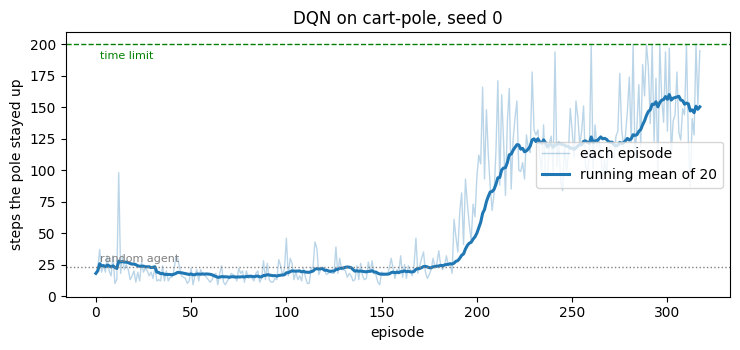

episode length, running mean of 20, at every 25th episode:
  25:24  50:17  75:15  100:17  125:20  150:18  175:23  200:47  225:117  250:118  275:120  300:158
episodes that reached the limit of 200: 7 of 318
the last 30 episodes, one by one: [159 200 182 137 200 123 173  97 200 157 138 194 131 197 112 139 144 178 130 124 149 144 200 124  87 141 128
 200 152 195]
  shortest 87, longest 200, largest jump between neighbours 103
best running mean: 160.1 at episode 302 | final running mean: 150.3


In [10]:
def running_mean(x, k=20):
    """The mean of the last k values (fewer at the start), one per episode."""
    c = np.cumsum(np.insert(np.asarray(x, dtype=float), 0, 0.0))
    return np.array([(c[i + 1] - c[max(0, i + 1 - k)]) / (i + 1 - max(0, i + 1 - k)) for i in range(len(x))])

L0 = run0["lengths"]; smooth0 = running_mean(L0)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(L0, color="tab:blue", alpha=0.3, lw=1, label="each episode")
ax.plot(smooth0, color="tab:blue", lw=2.2, label="running mean of 20")
ax.axhline(BASE["random"], color="grey", ls=":", lw=1); ax.text(2, BASE["random"] + 4, "random agent", fontsize=8, color="grey")
ax.axhline(MAX_LEN, color="green", ls="--", lw=1); ax.text(2, MAX_LEN - 12, "time limit", fontsize=8, color="green")
ax.set_xlabel("episode"); ax.set_ylabel("steps the pole stayed up"); ax.set_title("DQN on cart-pole, seed 0"); ax.legend(loc="center right")
plt.tight_layout(); plt.show()

print("episode length, running mean of 20, at every 25th episode:")
print("  " + "  ".join(f"{e + 1}:{smooth0[e]:.0f}" for e in range(24, len(L0), 25)))
print(f"episodes that reached the limit of {MAX_LEN}: {(L0 == MAX_LEN).sum()} of {len(L0)}")
print(f"the last 30 episodes, one by one: {L0[-30:]}")
print(f"  shortest {L0[-30:].min()}, longest {L0[-30:].max()}, largest jump between neighbours {np.abs(np.diff(L0[-30:])).max()}")
print(f"best running mean: {smooth0.max():.1f} at episode {smooth0.argmax() + 1} | final running mean: {smooth0[-1]:.1f}")

### Why we see this

The pale line is the truth and it is hard to read: episodes of 200 steps sit beside episodes of 60. The
running mean is what you can reason about, and every published reward curve is smoothed in some such
way. Remember that when you compare your raw curve with a figure in a paper.

The curve also does not climb like a supervised one. It lingers near the random level while epsilon is
high and the memory holds mostly aimless experience, rises quickly, then wobbles and sometimes drops.
Three things cause the drops: one move in twenty is still random; the data changes as the agent
changes (a better agent sees states the old one never reached, and has to learn them from scratch);
and each refresh of the target network shifts every target at once.

---
## Step 11 - Measure the policy, not the learner

The training curve was collected with exploration on and a 200-step limit. To judge the **policy**,
switch exploration off (Chapter 57's rule) and give it a longer limit than it was trained with: 500
steps, ten seconds. We also ask how each episode ended, and watch where the cart goes.

**Predict before you run:** one move in twenty was random during training. With exploration off, will
the score be much higher than the training average? When an episode fails, will it be the pole that
falls or the cart that leaves the track?

In [11]:
ev_len, ev_ends = evaluate(greedy(run0["W"]), episodes=20, max_len=500)
print("seed 0, exploration off, 20 episodes with a limit of 500 steps")
print("  lengths:", ev_len)
print(f"  mean {ev_len.mean():.1f} | shortest {ev_len.min()} | longest {ev_len.max()} | how they ended: {ev_ends}")
ev200, _ = evaluate(greedy(run0["W"]), episodes=20, max_len=MAX_LEN)
print(f"the same policy with the training limit of {MAX_LEN}: mean {ev200.mean():.1f}, reached the limit in {(ev200 == MAX_LEN).sum()} of 20")
print(f"for comparison: random {BASE['random']:.1f}, the one-line rule of Step 4 {BASE['lean and swing']:.1f}")
env = CartPole(999); s = env.reset(); xs = []
for t in range(500):
    s, r, done = env.step(greedy(run0["W"])(s)); xs.append(s[0])
    if done: break
print("cart position every 25 steps in one episode:", np.round(xs[24::25], 2))

seed 0, exploration off, 20 episodes with a limit of 500 steps
  lengths: [162 118 160 224 103 147 159 179 158 183 141 185 109 178 151 145 109 301  95 114]
  mean 156.1 | shortest 95 | longest 301 | how they ended: {'cart left the track': 11, 'pole fell': 9}


the same policy with the training limit of 200: mean 149.8, reached the limit in 2 of 20
for comparison: random 22.8, the one-line rule of Step 4 500.0
cart position every 25 steps in one episode: [0.05 0.09 0.2  0.45 0.95 1.88]


### Why we see this

With exploration off the policy scores about what it scored in training. The random moves were not
what was holding it back. It is far better than the random agent and nowhere near the one-line rule of
Step 4.

Look at how its episodes end and at the cart's position. In about half of them the pole never fell:
the cart ran off the end of the track. The agent has learnt the urgent half of the task, keeping the
pole up by chasing it, and not the patient half, bringing the cart back. That is what its experience
taught. A falling pole is punished within a second. A drift is punished a hundred steps after it
begins, and at a discount of 0.99 a consequence 150 steps away arrives multiplied by 0.99 ** 150, about
0.22, after travelling backwards through many updates (Chapter 57's "news travels one cell per visit").
Twenty thousand steps were enough for the first lesson and not for the second.

This is the usual shape of a deep-RL result: good at what the training experience showed often, weak
at what it showed rarely or late. A reward curve cannot tell you which is which. Watching the agent,
and asking how its episodes end, can.

---
## Step 12 - Take away the replay memory

Now the experiments the chapter is about. First, shrink the memory from 10,000 transitions to 64, the
size of one batch. Everything else is unchanged: the same network, the same number of gradient steps,
the same target network. The agent now learns only from the last 64 steps, about 1.3 seconds of
experience, which is one or two episodes at the start and a third of an episode later on.

Three seeds, because one run of anything in this subject is an anecdote.

**Predict before you run:** does the agent still learn? Better or worse than the full agent's last-20
average, and by how much?

In [12]:
SEEDS = (0, 1, 2)

def summarise(runs, label):
    last = np.array([r["lengths"][-20:].mean() for r in runs])
    best = np.array([running_mean(r["lengths"]).max() for r in runs])
    qmax = np.array([np.abs(r["q"]).max() for r in runs])
    print(f"{label:22s} last 20 episodes, per seed: {np.round(last, 1)}  mean {last.mean():6.1f}  (std {last.std():5.1f})")
    print(f"{'':22s} best running mean, per seed: {np.round(best, 1)} | largest mean q(s)[a] seen: {np.array2string(qmax, precision=0, floatmode='fixed')}")
    return last

t0 = time.time()
no_replay = [train_dqn(seed=sd, memory_size=BATCH, quiet=True) for sd in SEEDS]
print(f"three runs with a memory of {BATCH} transitions: {time.time() - t0:.0f} s")
last_no_replay = summarise(no_replay, "no replay (memory 64)")
print(f"\nfor comparison, the full agent, seed 0: last 20 episodes {run0['lengths'][-20:].mean():.1f}, best running mean {running_mean(run0['lengths']).max():.1f}")

three runs with a memory of 64 transitions: 78 s
no replay (memory 64)  last 20 episodes, per seed: [ 65.  120.6  90.6]  mean   92.1  (std  22.8)
                       best running mean, per seed: [ 92.1 136.1  90.6] | largest mean q(s)[a] seen: [40. 42. 45.]

for comparison, the full agent, seed 0: last 20 episodes 150.3, best running mean 160.1


### Why we see this

Without a long memory the agent still learns: every seed ends well above the random agent. But it
learns less, and its curve is rougher. In the saved run the three agents average about 92 steps over
their last 20 episodes, against about 164 for the full agent (Step 14 trains its other two seeds).

Each gradient step is now fitted to the latest second of experience, which is always one narrow
situation. While the pole is being balanced well, every stored transition says "all is fine", and
nothing in the memory rehearses what the network once knew about recovering from a bad lean. Then it
meets a bad lean. A network trained on one kind of example at a time forgets the others: that is true
in supervised learning too, and replay is the cure in both.

Notice what did **not** happen. The predicted values stayed in a sensible range. The target network
was still there.

---
## Step 13 - Take away the target network instead

Put the memory back to 10,000 and remove the other repair: `use_target=False` makes the Q-network
compute its own targets. Nothing is frozen. Every gradient step changes the prediction **and** the
target it is being moved towards.

Watch the column `mean q(s)[a]` in the log. Recall the ceiling: no state can truly be worth more than
100.

**Predict before you run:** the true values are at most 100. What will the network's predictions do?
And recall Step 3: what does an agent that lasts 9 or 10 steps have to be doing?

In [13]:
t0 = time.time()
print("no target network, seed 0")
no_target = [train_dqn(seed=0, use_target=False)]
no_target += [train_dqn(seed=sd, use_target=False, quiet=True) for sd in SEEDS[1:]]
print(f"\nthree runs without a target network: {time.time() - t0:.0f} s")
last_no_target = summarise(no_target, "no target network")
ev_nt, ends_nt = evaluate(greedy(no_target[0]["W"]), episodes=20, max_len=500)
acts = [greedy(no_target[0]["W"])(st) for st in memory.s[:3000]]
print(f"\nseed 0 with exploration off: mean {ev_nt.mean():.1f} steps, {ends_nt}")
print(f"its greedy action in 3,000 varied states: pushes right in {100 * np.mean(acts):.1f}% of them")
print(f"its mean prediction after 100, 500, 1,000, 2,000 and {no_target[0]['updates']:,} gradient steps: "
      + ", ".join(f"{no_target[0]['q'][k - 1]:,.0f}" for k in (100, 500, 1000, 2000, no_target[0]["updates"])))
first = int(np.argmax(no_target[0]["q"] > 100)) + 1
print(f"its mean prediction first passed the ceiling of 100 at gradient step {first} (step {WARM_UP + TRAIN_EVERY * (first - 1):,} of experience, "
      f"epsilon {max(EPS_END, 1.0 - (1.0 - EPS_END) * (WARM_UP + TRAIN_EVERY * (first - 1)) / EPS_STEPS):.2f})")
print(f"the full agent's (seed 0) at the same points: "
      + ", ".join(f"{run0['q'][k - 1]:,.1f}" for k in (100, 500, 1000, 2000, run0["updates"])))

no target network, seed 0


  step   2500 | episodes   136 | epsilon 0.53 | last 20 episodes:   14.0 steps | mean q(s)[a]       2464.0


  step   5000 | episodes   355 | epsilon 0.05 | last 20 episodes:    9.3 steps | mean q(s)[a]      49518.0


  step   7500 | episodes   613 | epsilon 0.05 | last 20 episodes:    9.8 steps | mean q(s)[a]     208672.0


  step  10000 | episodes   871 | epsilon 0.05 | last 20 episodes:    9.3 steps | mean q(s)[a]     515687.1


  step  12500 | episodes  1132 | epsilon 0.05 | last 20 episodes:    9.2 steps | mean q(s)[a]    1123940.9


  step  15000 | episodes  1395 | epsilon 0.05 | last 20 episodes:    9.6 steps | mean q(s)[a]    1921869.9


  step  17500 | episodes  1653 | epsilon 0.05 | last 20 episodes:    9.6 steps | mean q(s)[a]    2838665.2


  step  20000 | episodes  1916 | epsilon 0.05 | last 20 episodes:    9.2 steps | mean q(s)[a]    3963158.5



three runs without a target network: 71 s
no target network      last 20 episodes, per seed: [9.2 9.6 9.6]  mean    9.4  (std   0.2)
                       best running mean, per seed: [27.8 65.5 40.5] | largest mean q(s)[a] seen: [4481023. 4046174. 4773346.]

seed 0 with exploration off: mean 9.5 steps, {'pole fell': 20}
its greedy action in 3,000 varied states: pushes right in 0.0% of them
its mean prediction after 100, 500, 1,000, 2,000 and 4,876 gradient steps: 11, 3,028, 40,397, 347,728, 4,167,495
its mean prediction first passed the ceiling of 100 at gradient step 203 (step 1,308 of experience, epsilon 0.75)
the full agent's (seed 0) at the same points: 1.1, 5.1, 9.5, 19.2, 39.5


### Why we see this

This is the failure the chapter calls the moving target. The network is asked to make `q(s)` equal to
`1 + 0.99 * q(s2)`. But `s` and `s2` are almost the same four numbers, and both values come out of the
same weights. Raise `q(s)` and `q(s2)` rises with it, which raises the target, which asks for `q(s)` to
be raised again. With a frozen copy the target stands still for 100 gradient steps and the network has
something fixed to fit. Without it the loop feeds itself, and the predictions leave the range of
anything that could be true: compare them with the ceiling of 100.

Once the values are that large, the difference between the two actions' values is set by the runaway
and not by the pole. The agent ends up preferring one action nearly everywhere, and Step 3 told you
what pushing one way on every step earns: under ten steps, **worse than a random agent**.

Be careful what you conclude. This is one small network on one task, with three seeds. On other tasks,
and with other networks, DQN without a target network can limp along or even work. (Trial 3 below asks
whether a smaller learning rate is enough to rescue it here.) What the experiment shows is the
mechanism and how violent it can be, not a law.

---
## Step 14 - Three seeds, three stories

Step 9 trained the full agent once. Train it twice more, from seeds 1 and 2, and put all nine runs of
Steps 9 to 13 in one picture. To compare runs with very different numbers of episodes, the curves are
drawn against **steps of experience**: at each point, the mean length of the last 20 episodes finished
so far.

**Predict before you run:** the three seeds of the full agent differ only in the starting weights and
the dice. How far apart will their last-20 averages be: within 5 steps of each other, 20, 50?

two more runs of the full agent: 40 s

full DQN               last 20 episodes, per seed: [150.4 194.6 147. ]  mean  163.9  (std  21.7)
                       best running mean, per seed: [160.1 195.3 167.6] | largest mean q(s)[a] seen: [40. 40. 41.]
no replay (memory 64)  last 20 episodes, per seed: [ 65.  120.6  90.6]  mean   92.1  (std  22.8)
                       best running mean, per seed: [ 92.1 136.1  90.6] | largest mean q(s)[a] seen: [40. 42. 45.]
no target network      last 20 episodes, per seed: [9.2 9.6 9.6]  mean    9.4  (std   0.2)
                       best running mean, per seed: [27.8 65.5 40.5] | largest mean q(s)[a] seen: [4481023. 4046174. 4773346.]


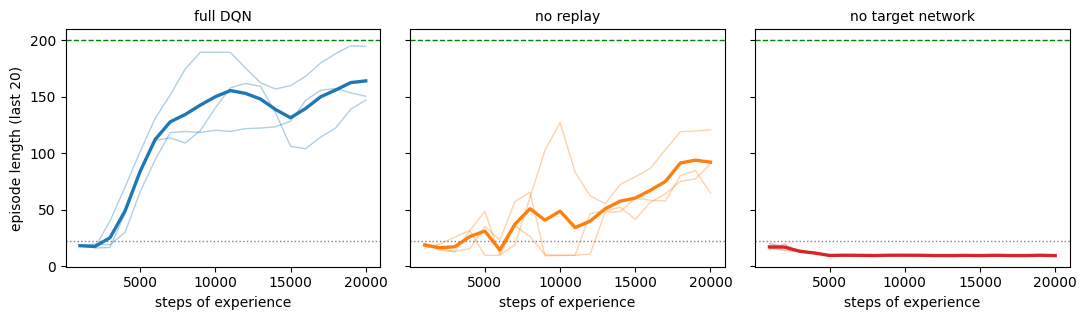


mean of three seeds, at every 2,000 steps of experience
             steps   2000   4000   6000   8000  10000  12000  14000  16000  18000  20000
          full DQN     18     49    112    134    150    153    139    140    156    164
         no replay     16     26     14     51     49     40     58     67     91     92
 no target network     17     12     10     10     10     10     10     10      9      9

the full agent, seed by seed
            seed 0     20     30     94    119    120    122    123    147    157    150
            seed 1     17     70    131    174    189    175    157    168    188    195
            seed 2     16     47    111    109    140    162    136    104    122    147

largest gap between two seeds of the full agent at any point: 71 steps (at step 9,000)

exploration off, 20 episodes, limit 500


          full DQN  per seed: [156.  186.3 142.5]  mean  161.6  (std  18.3)
         no replay  per seed: [ 58.1 115.9 117.4]  mean   97.1  (std  27.6)


 no target network  per seed: [9.5 9.4 9.5]  mean    9.5  (std   0.1)


In [14]:
t0 = time.time()
full = [run0] + [train_dqn(seed=sd, quiet=True) for sd in SEEDS[1:]]
print(f"two more runs of the full agent: {time.time() - t0:.0f} s\n")
last_full = summarise(full, "full DQN")
summarise(no_replay, "no replay (memory 64)")
summarise(no_target, "no target network")

GRID = np.arange(1000, STEPS + 1, 1000)
def on_steps(run):
    """Mean length of the last 20 episodes that had finished by each step of GRID."""
    out = []
    for g in GRID:
        done_by = run["lengths"][run["ended_at"] <= g]
        out.append(done_by[-20:].mean() if len(done_by) else np.nan)
    return np.array(out)

CURVES = {name: np.array([on_steps(r) for r in runs])
          for name, runs in (("full DQN", full), ("no replay", no_replay), ("no target network", no_target))}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), sharey=True)
for ax, (name, C), colour in zip(axes, CURVES.items(), ("tab:blue", "tab:orange", "tab:red")):
    for row in C: ax.plot(GRID, row, color=colour, alpha=0.35, lw=1)
    ax.plot(GRID, C.mean(axis=0), color=colour, lw=2.4)
    ax.axhline(BASE["random"], color="grey", ls=":", lw=1); ax.axhline(MAX_LEN, color="green", ls="--", lw=1)
    ax.set_title(name, fontsize=10); ax.set_xlabel("steps of experience")
axes[0].set_ylabel("episode length (last 20)")
plt.tight_layout(); plt.show()

print("\nmean of three seeds, at every 2,000 steps of experience")
print(f"{'steps':>18s} " + " ".join(f"{g:6d}" for g in GRID[1::2]))
for name, C in CURVES.items():
    print(f"{name:>18s} " + " ".join(f"{v:6.0f}" for v in C.mean(axis=0)[1::2]))
print("\nthe full agent, seed by seed")
for sd, row in zip(SEEDS, CURVES["full DQN"]):
    print(f"{'seed ' + str(sd):>18s} " + " ".join(f"{v:6.0f}" for v in row[1::2]))
spread = CURVES["full DQN"].max(axis=0) - CURVES["full DQN"].min(axis=0)
print(f"\nlargest gap between two seeds of the full agent at any point: {np.nanmax(spread):.0f} steps (at step {GRID[np.nanargmax(spread)]:,})")

print("\nexploration off, 20 episodes, limit 500")
EVAL = {}
for name, runs in (("full DQN", full), ("no replay", no_replay), ("no target network", no_target)):
    per_seed = [evaluate(greedy(r["W"]), episodes=20, max_len=500)[0].mean() for r in runs]
    EVAL[name] = per_seed
    print(f"{name:>18s}  per seed: {np.round(per_seed, 1)}  mean {np.mean(per_seed):6.1f}  (std {np.std(per_seed):5.1f})")

### Why we see this

Read the table across before you read it down. The three seeds of one and the same agent are not the
same curve: they rise at different times, peak at different heights and end in different places.
Nothing distinguishes them except the random starting weights and the dice. In supervised learning
three seeds of a small model usually agree to within a point of accuracy. Here a small early
difference changes which states are visited, which changes the data, which changes the network: the
learner is inside its own feedback loop.

Now down. The gap between the full agent and the agent without a target network is many times larger
than the gap between seeds: that conclusion is safe. For the agent without replay, do the sum. In the
saved run the gap to the full agent is about 70 steps, the spread between seeds is a little over 20,
and the best seed without replay is below the worst seed with it. So "replay helped here" is a fair
reading, and "replay is worth 70 steps" is not: with three seeds the size of the effect is known only
roughly. Three seeds are the least that lets you ask the question. Published comparisons use five to
ten, or more, and report the spread.

---
## Step 15 - A different idea: learn the policy directly (REINFORCE)

Everything so far learnt **values** and acted by picking the larger one. The other family learns the
**policy** itself: a network that takes the state and returns a probability for each action. It is a
classifier, softmax and all (Chapter 5), with one difference: nobody supplies the label.

**REINFORCE** fills in for the label like this.

1. Play a whole episode, choosing each action by rolling dice with the network's probabilities.
2. For every step, compute the **return that followed it**: Chapter 57's discounted sum of the rewards
   from that step to the end.
3. Do one gradient step on the loss `cross-entropy(action taken) x return`. The action that was taken
   is used as if it were the right label, and the return says how hard to believe it.

So an action followed by a long survival is made much more likely, and one followed by a quick fall
only a little. That is all a **policy gradient** is: the classification gradient of Chapter 6, weighted
by how well things went afterwards.

There is no memory, no target network, no epsilon (the dice of the policy do the exploring) and no
maximum over actions. The price is that an episode's data is used once and thrown away: the method is
**on-policy**.

The policy network is Dense 4 -> 32 -> 2 with a softmax: `4 x 32 + 32 = 160` and `32 x 2 + 2 = 66`,
**226** parameters. We give it the same 20,000 steps of experience as each DQN run.

**Predict before you run:** every reward is +1, so every return is positive, so every action taken is
made **more** likely, the bad ones included. Can that learn anything?

In [15]:
def build_policy(seed):
    keras.utils.set_random_seed(seed)
    return keras.Sequential([
        layers.Input(shape=(4,)),
        layers.Dense(32, activation="relu"),
        layers.Dense(2, activation="softmax"),         # probabilities of pushing left and right
    ])

def action_probs(W, s):
    """The policy network's forward pass in NumPy: the probabilities of the two actions."""
    z = np.maximum(s @ W[0] + W[1], 0.0) @ W[2] + W[3]
    z = np.exp(z - z.max())
    return z / z.sum()

def returns_to_go(n_steps, gamma=GAMMA):
    """The discounted return that followed each step of an episode of n_steps rewards of +1."""
    G = np.zeros(n_steps, np.float32); g = 0.0
    for k in range(n_steps - 1, -1, -1):
        g = 1.0 + gamma * g
        G[k] = g
    return G

def train_reinforce(seed=0, steps=STEPS, baseline=True, lr=0.01):
    """REINFORCE. baseline=True subtracts the episode's average return from every return before weighting."""
    policy = build_policy(seed)
    optimizer = keras.optimizers.Adam(lr)

    @tf.function(autograph=False, input_signature=[tf.TensorSpec([None, 4], tf.float32),      # any episode length
                                                   tf.TensorSpec([None], tf.int32), tf.TensorSpec([None], tf.float32)])
    def update(s, a, weight):
        with tf.GradientTape() as tape:
            ce = keras.losses.sparse_categorical_crossentropy(a, policy(s))   # -log p(action taken): Chapter 6
            loss = tf.reduce_mean(ce * weight)                                # ...weighted by what followed
        grads = tape.gradient(loss, policy.trainable_variables)
        optimizer.apply_gradients(zip(grads, policy.trainable_variables))
        return loss

    env, rng = CartPole(seed), np.random.default_rng(seed)
    W = weights_of(policy)
    lengths, ended_at, total = [], [], 0
    while total < steps:
        s = env.reset(); S, A = [], []
        for t in range(1, MAX_LEN + 1):                                # 1. play one whole episode
            a = int(rng.random() < action_probs(W, s)[1])              #    the policy's own dice
            S.append(s); A.append(a)
            s, r, done = env.step(a)
            if done: break
        G = returns_to_go(t)                                           # 2. the return that followed each step
        weight = G - G.mean() if baseline else G                       #    with or without a baseline
        update(np.array(S, np.float32), np.array(A, np.int32), weight)  # 3. one gradient step
        W = weights_of(policy)
        total += t; lengths.append(t); ended_at.append(total)
    return dict(lengths=np.array(lengths), ended_at=np.array(ended_at), W=W, policy=policy, seed=seed)

p = build_policy(0)
assert p.count_params() == (4 * 32 + 32) + (32 * 2 + 2) == 226
print("policy network parameters:", p.count_params(), "| probabilities for one state before training:", action_probs(weights_of(p), batch[0]))
G = returns_to_go(30)
print("returns that followed steps 1, 2, 3 ... 28, 29, 30 of a 30-step episode:", G[:3], "...", G[-3:])
print("  minus their average:", (G - G.mean())[:3], "...", (G - G.mean())[-3:])

t0 = time.time()
rf0 = train_reinforce(seed=0)
print(f"\nREINFORCE with a baseline, seed 0: {len(rf0['lengths'])} episodes in {time.time() - t0:.1f} s")
sm = running_mean(rf0["lengths"])
print("episode length, running mean of 20, at every 25th episode:")
print("  " + "  ".join(f"{e + 1}:{sm[e]:.0f}" for e in range(24, len(sm), 25)))
print(f"last 20 episodes: {rf0['lengths'][-20:].mean():.1f} (limit {MAX_LEN})")

policy network parameters: 226 | probabilities for one state before training: [0.499 0.501]
returns that followed steps 1, 2, 3 ... 28, 29, 30 of a 30-step episode: [26.03  25.283 24.528] ... [2.97 1.99 1.  ]
  minus their average: [11.929 11.182 10.427] ... [-11.131 -12.111 -13.101]



REINFORCE with a baseline, seed 0: 147 episodes in 1.5 s
episode length, running mean of 20, at every 25th episode:
  25:40  50:69  75:166  100:171  125:190
last 20 episodes: 200.0 (limit 200)


### Why we see this

Look at the returns of the 30-step episode. The first action was followed by 30 steps of survival and
the last by one, so the first is weighted far more heavily than the last. That is sensible: the last
few actions before a fall are the suspects.

The line "minus their average" is the **baseline**. Without it, every weight is positive and every
action taken is pushed up, the good ones more than the bad ones. Learning is still possible, because
only the differences matter, but the signal is a small difference between large numbers. Subtract the
average and the early actions get a positive weight ("do more of this") and the late ones a negative
weight ("do less of this"). The expected gradient is the same. Its noise is much smaller.

---
## Step 16 - With and without the baseline, and against DQN

Five seeds of REINFORCE with the baseline and five without, each on the same 20,000 steps of experience
as a DQN run. The only difference between the two versions is the subtraction.

**Predict before you run:** which does better? And will REINFORCE, with 226 parameters and no replay,
do worse than the 4,610-parameter DQN with all its machinery?

nine more REINFORCE runs: 16 s

agent                     last 20 training episodes, per seed   mean   std |     exploration off, limit 500   mean


full DQN                                          150 195 147  163.9  21.7 |                    156 186 142  161.6


DQN, no replay                                      65 121 91   92.1  22.8 |                     58 116 117   97.1
DQN, no target net                                    9 10 10    9.4   0.2 |                        10 9 10    9.5


REINFORCE with baseline                   200 191 118 191 200  180.1  31.2 |            500 500 212 484 500  439.1


REINFORCE, no baseline                    131 120 188 179 194  162.8  30.8 |            187 132 219 303 414  251.2
                  full DQN, mean over seeds at every 2,000 steps:   18   49  112  134  150  153  139  140  156  164
   REINFORCE with baseline, mean over seeds at every 2,000 steps:   56   98  145  156  153  155  174  185  169  179
    REINFORCE, no baseline, mean over seeds at every 2,000 steps:   37   46   78   71  101  141  137  106  117  159


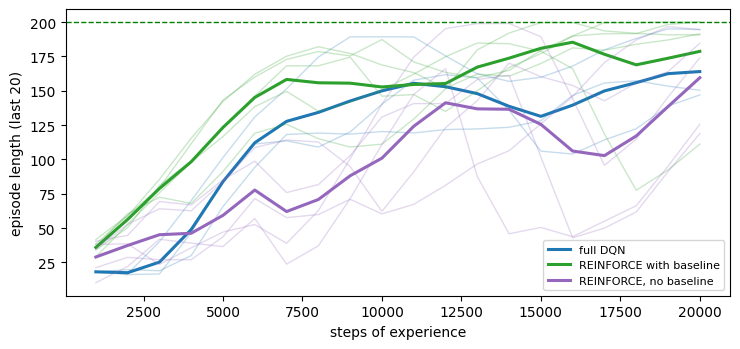

In [16]:
t0 = time.time()
RF_SEEDS = (0, 1, 2, 3, 4)                             # a REINFORCE run takes seconds, so we can afford five
rf_base = [rf0] + [train_reinforce(seed=sd) for sd in RF_SEEDS[1:]]
rf_none = [train_reinforce(seed=sd, baseline=False) for sd in RF_SEEDS]
print(f"nine more REINFORCE runs: {time.time() - t0:.0f} s\n")

def policy_greedy(W):
    return lambda s: int(np.argmax(action_probs(W, s)))

print(f"{'agent':24s} {'last 20 training episodes, per seed':>36s} {'mean':>6s} {'std':>5s} | {'exploration off, limit 500':>30s} {'mean':>6s}")
TABLE = {}
for name, runs, act in (("full DQN", full, greedy), ("DQN, no replay", no_replay, greedy), ("DQN, no target net", no_target, greedy),
                        ("REINFORCE with baseline", rf_base, policy_greedy), ("REINFORCE, no baseline", rf_none, policy_greedy)):
    last = np.array([r["lengths"][-20:].mean() for r in runs])
    ev = np.array([evaluate(act(r["W"]), episodes=20, max_len=500)[0].mean() for r in runs])
    TABLE[name] = (last, ev)
    print(f"{name:24s} {' '.join(f'{v:.0f}' for v in last):>36s} {last.mean():6.1f} {last.std():5.1f} | {' '.join(f'{v:.0f}' for v in ev):>30s} {ev.mean():6.1f}")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
for name, runs, colour in (("full DQN", full, "tab:blue"), ("REINFORCE with baseline", rf_base, "tab:green"),
                           ("REINFORCE, no baseline", rf_none, "tab:purple")):
    C = np.array([on_steps(r) for r in runs])
    for row in C: ax.plot(GRID, row, color=colour, alpha=0.25, lw=1)
    ax.plot(GRID, np.nanmean(C, axis=0), color=colour, lw=2.2, label=name)
    print(f"{name:>26s}, mean over seeds at every 2,000 steps: " + " ".join(f"{v:4.0f}" for v in np.nanmean(C, axis=0)[1::2]))
ax.axhline(MAX_LEN, color="green", ls="--", lw=1)
ax.set_xlabel("steps of experience"); ax.set_ylabel("episode length (last 20)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Why we see this

Three things, in order of how sure you can be of them.

**REINFORCE learns this task, with or without the baseline.** Even with every weight positive, the
returns differ: early actions of an episode get large ones, the last few before a fall get small ones,
and a long episode pushes harder than a short one. The differences carry the signal.

**The baseline helps, but less than the textbook story suggests at this size.** In the saved run it
learns faster in the first few thousand steps and its policies do better with exploration off, but in
the last 20 training episodes its advantage is smaller than the spread between seeds. Cart-pole pays a
reward at every step and its episodes are short, so the noise a baseline removes is not what limits
learning here. On long tasks with rare rewards it is.

**On this task the simplest policy-gradient method is a match for DQN or better**, with a twentieth
of the parameters, none of the machinery and a fraction of the computing time; with exploration off
most of its policies reach the 500-step limit, which no DQN policy here does. Do not read that as
"policy gradients beat DQN". Cart-pole suits them: reward at every step, and a right answer that is a
simple function of the state (Step 4's rule is one line). Where each step of experience is costly,
throwing every episode away after one use is a serious handicap, and value methods with replay are
the frugal choice.

What the comparison does show is the trade the chapter describes. DQN reuses its data and is touchy
about its targets. REINFORCE has a plain gradient, uses each episode once, and is noisy: look at how
far apart its seeds are.

---
## Trials: change one thing at a time

Each trial is one changed argument. Write the prediction first. Use at least the three seeds of `SEEDS`,
and compare the difference you see with the spread between seeds before believing it.

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | `train_dqn(sync_every=1000)` (refresh the target every 4,000 steps) | Faster or slower learning? More or less stable? | |
| 2 | `train_dqn(sync_every=5)` | Closer to the full agent or to "no target network"? | |
| 3 | `train_dqn(use_target=False, lr=1e-4)` | Does a smaller learning rate stop the blow-up, or only delay it? Watch `mean q(s)[a]`. | |
| 4 | `train_dqn(double=True)` | What happens to `mean q(s)[a]` compared with the full agent? To the episode length? | |
| 5 | `train_dqn(memory_size=1000)` | Between the full agent and "no replay", or as good as the full agent? | |
| 6 | `train_dqn(lr=1e-2)` | A learning rate that would be fine for a small classifier. What does it do here? | |
| 7 | In `train_dqn`, store `done or t_ep == MAX_LEN` in the memory instead of `done` | The agent is told that step 200 is a fall. What should happen to its values near step 200, and to its score? | |
| 8 | `train_reinforce(lr=0.05)` | More speed, or collapse? | |

## Exercises

1. **Count it.** Change the Q-network to one hidden layer of 128 units. Work out the parameter count by
   hand, change the `assert`, and compare three seeds with the two-layer network.
2. **A fairer evaluation.** Train the full agent with `MAX_LEN = 500` (and `STEPS = 40000`). Does the
   cart still drift off the track in the 500-step evaluation of Step 11? Explain what changed in the
   data.
3. **Reward scale.** Multiply the reward by 100 inside `CartPole.step`. Before running: what happens to
   the targets, to the Huber loss (which part of it are you now in?), and to learning? Then divide by
   100 instead.
4. **A learnt baseline.** In `train_reinforce`, replace the episode's average return by the output of a
   second small network trained to predict the return from the state. You have built an actor and a
   critic. Does the spread between seeds change?
5. **Five seeds.** Rerun Step 14 with `SEEDS = (0, 1, 2, 3, 4)`. Does the order of the three agents
   change? Does the size of the gap between "full" and "no replay"?
6. **Break the physics.** Flip the sign of `GRAVITY`. Which of Step 3's checks catches it? Now train an
   agent in the broken world anyway and describe what it learns.

## Cheat sheet

| Idea | One line |
|---|---|
| environment | `reset() -> state`, `step(action) -> (state, reward, done)`; test the physics before learning in it |
| Q-network | state in, one value per action out, no activation on the output; here 4 -> 64 -> 64 -> 2 = 4,610 parameters |
| acting | a NumPy forward pass of the copied weights; never `model.predict` once per step |
| target | `r + gamma * (1 - done) * max(q_target(s2))`, computed outside the gradient tape |
| `done` | true only for a real ending; a time limit is not an ending |
| replay memory | store transitions, train on random batches: breaks correlation, reuses data; needs an off-policy method |
| target network | a frozen copy that supplies the targets; refreshed every so often |
| Huber loss | squared for small errors, linear for large: one wild target cannot dominate |
| what to watch | episode length (smoothed) and the size of the predicted values, not the loss |
| evaluation | exploration off, a longer limit than training, and how the episodes ended |
| REINFORCE | cross-entropy on the action taken, weighted by the return that followed; subtract a baseline |
| reporting | several seeds, the spread, and the settings; one curve is an anecdote |

In [17]:
print(f"whole notebook: {time.time() - T_START:.0f} s")

whole notebook: 228 s
